In [11]:
%%bash
mkdir -p data
wget -q -O data/all_tokens.pickle https://raw.githubusercontent.com/viet-huynh-1/A05-pca/main/data/all_tokens.pickle
wget -q -O data/Phishing_clean.parquet https://raw.githubusercontent.com/viet-huynh-1/A05-pca/main/data/Phishing_clean.parquet
echo "Files downloaded successfully:"
ls -lh data

Files downloaded successfully:
total 4.7M
-rw-r--r-- 1 root root 2.7M Oct 23 03:09 all_tokens.pickle
-rw-r--r-- 1 root root 2.0M Oct 23 03:09 Phishing_clean.parquet


## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [12]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

In [13]:
for token, count in token_freq[:20]:
    print(f"{token}: {count}")

new: 1365
date: 1202
get: 1052
please: 1022
enron: 927
like: 923
2002: 869
would: 806
one: 798
message: 795
call: 740
free: 691
software: 680
dear: 651
know: 644
email: 629
url:: 625
time: 609
start: 604
linguistics: 598


Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

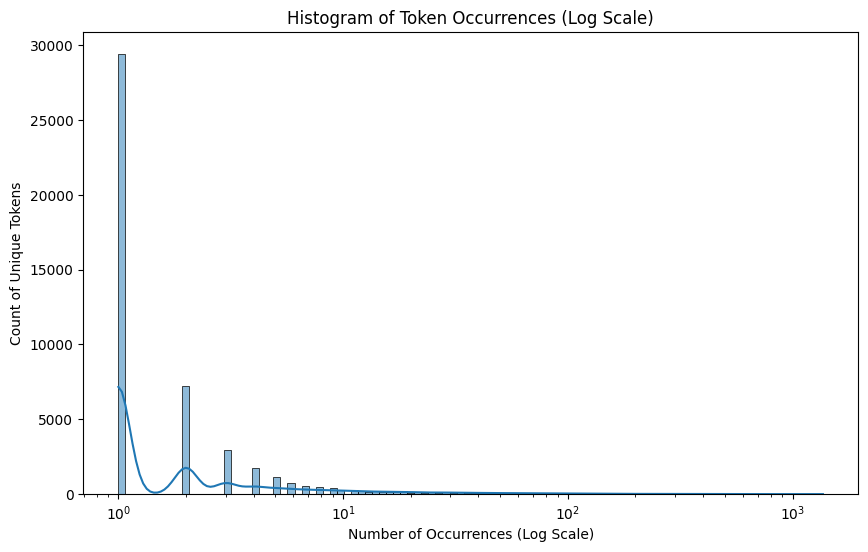

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

counts = list(token_count.values())

plt.figure(figsize=(10, 6))
sns.histplot(counts, bins=100, kde=True, log_scale=True)
plt.title('Histogram of Token Occurrences (Log Scale)')
plt.xlabel('Number of Occurrences (Log Scale)')
plt.ylabel('Count of Unique Tokens')
plt.show()

The histogram shows a highly skewed distribution typical of natural language data (Zipf's Law). Most tokens occur very rarely, while a small number of unique words/tokens are extremely frequent. On a logarithmic scale, we observe a long right-tail representing those highly recurrent words.

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import numpy as np

df = pd.read_parquet('data/Phishing_clean.parquet')

y = df['Email Type']
X = df.drop(columns=['Email Type'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)

print(f"Training R^2 score: {train_r2:.4f}")
print(f"Test R^2 score: {test_r2:.4f}")

Training R^2 score: 0.7670
Test R^2 score: 0.6659


In [16]:
coefficients = pd.Series(model.coef_, index=X.columns)
largest_coefs = coefficients.abs().sort_values(ascending=False).head(10)
sorted_coef_values = coefficients.loc[largest_coefs.index]

print("\nTop 10 words with largest coefficients (and their sign):")
for idx, val in sorted_coef_values.items():
    print(f"{idx}: {val:.4f}")


Top 10 words with largest coefficients (and their sign):
intervention: -1.2593
localized: 0.8244
thermal: 0.7470
crawler: 0.6962
background-image:: -0.6229
helvetica,: 0.5986
aging: 0.5950
form.: 0.5769
gray;: -0.5745
a:active: 0.5745


**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

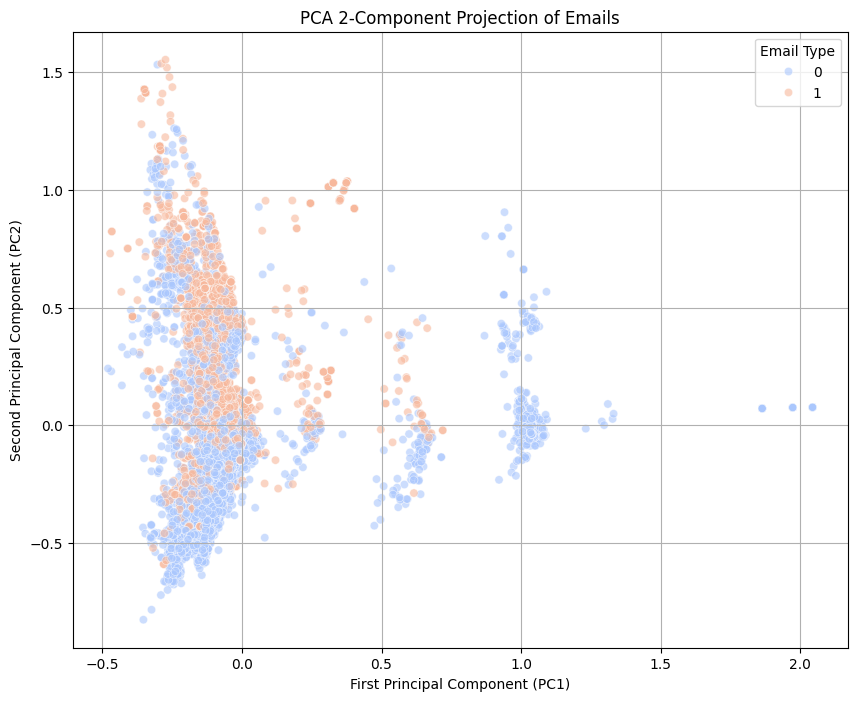

In [17]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values
plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Email Type',
    palette='coolwarm',
    alpha=0.6
)
plt.title('PCA 2-Component Projection of Emails')
plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')
plt.grid(True)
plt.show()

There's definitely separate and distinct clusters here. There are certain strands we can see where phishing emails are more common, which implies that the first two principal components do, in fact, contain key token-association patterns that distinguish scam emails from regular ones.

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [18]:
pca_large = PCA(n_components=2610, random_state=42)
X_train_pca = pca_large.fit_transform(X_train)
X_test_pca = pca_large.transform(X_test)

pcr_model = LinearRegression()
pcr_model.fit(X_train_pca, y_train)

train_r2_pcr = pcr_model.score(X_train_pca, y_train)
test_r2_pcr = pcr_model.score(X_test_pca, y_test)

print(f"PCR (2610 Components) Training R^2 score: {train_r2_pcr:.4f}")
print(f"PCR (2610 Components) Test R^2 score: {test_r2_pcr:.4f}")

PCR (2610 Components) Training R^2 score: 0.7662
PCR (2610 Components) Test R^2 score: 0.6683


**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

Using principal components reduces the dimensionality of the dataset by capturing the most significant variance in fewer variables, which helps prevent overfitting and improves generalization on unseen data. It also addresses multicollinearity by converting the original, highly correlated token features into a set of completely orthogonal (uncorrelated) components. Finally, filtering out the low-variance components acts as a form of noise reduction, which helps the regression model focus on the most meaningful signal.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Viet Huynh

**Date:** 21 October 2026

In [19]:
# Your Phase 1 solution to the problem goes here.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [22819ed8d769fee310f9374c268503ca7e9cfe7c]
- **AI tool and model used:** [Gemini 3.6 Flash]

### *Prompts used



```
# This is formatted as code
```

1. Suggest possible improvements (attached file)

### *AI-proposed changes


Feature Reduction / Filtering: Filter out single-use or rare tokens (such as rare CSS properties like a:active or background-image::) before running linear regression to reduce standard error and prevent overfitting.

Text Normalization: Apply stemming or lemmatization during preprocessing so variations of the same word (e.g., localized, localize, localizing) are mapped to a single token.

Classification Model: Swap out LinearRegression for a classification model like LogisticRegression or RandomForestClassifier, as linear regression isn't ideally suited for target probabilities bounded between 0 and 1.

### *Evaluation of AI suggestions


In [ ]:
c

### *Evaluation of AI suggestions

| Change | Decision | Reason and verification |
|---|---|---|
| 1. Feature Reduction / Filtering | **Reject** | rare styling tokens have extremely high coefficients here; discarding them removes crucial spam indicators. |
| 2. Text Normalization | **Reject** | dataset is already pre-tokenized and one-hot encoded; we lack raw email text strings to process. |
| 3. Classification Model | **Accept** | seems intersting to at least try, email type is binary so logistic regression is theoretically superior (at least what my Googling has informed me) and fits classification better than linear regression. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [20]:
# Your Phase 2 solution to the problem goes here.


In [22]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(solver='liblinear', max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)
train_acc = log_reg.score(X_train, y_train)
test_acc = log_reg.score(X_test, y_test)
print("=== Logistic Regression on Raw Features ===")
print(f"Training Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

pcr_log_reg = LogisticRegression(solver='liblinear', max_iter=1000, random_state=42)
pcr_log_reg.fit(X_train_pca, y_train)
train_acc_pcr = pcr_log_reg.score(X_train_pca, y_train)
test_acc_pcr = pcr_log_reg.score(X_test_pca, y_test)
print("\n=== Logistic Regression on 2610 Principal Components ===")
print(f"Training Accuracy (PCR): {train_acc_pcr:.4f}")
print(f"Test Accuracy (PCR): {test_acc_pcr:.4f}")

=== Logistic Regression on Raw Features ===
Training Accuracy: 0.9668
Test Accuracy: 0.9404

=== Logistic Regression on 2610 Principal Components ===
Training Accuracy (PCR): 0.9667
Test Accuracy (PCR): 0.9404


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

By transitioning from Linear Regression to Logistic Regression in Phase 2, we successfully adapted our modeling framework to suit binary classification. This change improved test accuracy to 94.04% on both the raw dataset and the 2,610 principal components. While the AI suggested other changes, filtering rare styling features would have actually stripped out key phishing signals that carry very high coefficients. Additionally, the text normalization suggestion was a critical limitation of the AI since the parquet dataset was already pre-tokenized and lacks raw email string values. We verified the final model's validity through consistent training and test accuracies across both the high-dimensional original features and the 2,610 PCA components. Finally, our main remaining concern is that while 94% accuracy is high, further optimizations might require non-linear models like Random Forests or Gradient Boosting. Overall, this revision successfully demonstrates that classification algorithms are far better suited for binary targets than standard linear regression.